In [1]:
import pandas as pd

In [2]:
xls = pd.ExcelFile('../data/raw/online_retail_II.xlsx')
period_one = pd.read_excel(xls, 'Year 2009-2010')
period_two = pd.read_excel(xls, 'Year 2010-2011')

In [3]:
period_one.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [4]:
period_two.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Exploratory Data Analysis `Online Retail II`

Transactional dataset of a UK-based online giftware retailer (2009-12 -> 2011-12). All values are in **Pounds sterling (GBP, £)**.

**Sections**
1. Data Overview & Initial Inspection (incl. duplicate investigation)
2. Missing Data Analysis
3. Descriptive Statistics
4. Univariate Analysis
5. Bivariate & Multivariate Analysis
6. Outlier & Anomaly Detection
7. Data Product: Fact Layer + Cleaning Funnel (+ return-rate view)
8. RFM Recency / Frequency / Monetary Segments
9. Insights & Data-Prep Action Plan

Goal: turn raw transactions into
- a **flagged fact table** (`retail_fact.parquet`) that keeps *every row* for sales-KPI dashboards, and
- a cleaned **RFM table with segment labels** (`retail_cleaned.parquet`) for CRM modelling.

In [1]:
import os
import gc
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.titleweight': 'bold'})
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

print('pandas', pd.__version__, '| numpy', np.__version__, '| matplotlib', matplotlib.__version__, '| seaborn', sns.__version__)

pandas 2.1.4 | numpy 1.26.4 | matplotlib 3.11.2 | seaborn 0.13.2


### Data Overview & Initial Inspection

- Both sheets are concatenated into one `df`; a parquet cache is kept in `data/processed/` so re-runs are fast (Excel reads take ~1 min per sheet).
- `Invoice` / `StockCode` / `Description` contain mixed types (numbers + text codes) from Excel, so they are coerced to string.

In [2]:
cache = '../data/processed/retail_raw_combined.parquet'
if os.path.exists(cache):
    df = pd.read_parquet(cache)
    # del period_one, period_two
else:
    df = pd.concat([period_one, period_two], ignore_index=True)
    for col in df.columns[df.dtypes == 'object']:
        s = df[col]
        df[col] = s.where(s.isna(), s.astype(str))
    df.to_parquet(cache, index=False)
    del period_one, period_two
print('combined shape:', df.shape)
for col in ['Invoice', 'StockCode', 'Description', 'Country']:
    df[col] = df[col].astype('str')

combined shape: (1067371, 8)


In [3]:
print(
    f"rows: {len(df):,}   columns: {df.shape[1]}\n"
    f"date range: {df.InvoiceDate.min()}  ->  {df.InvoiceDate.max()}"
)

overview = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'nulls': df.isna().sum(),
    'n_unique': [df[c].nunique(dropna=False) for c in df.columns],
    'sample_values': [list(df[c].dropna().unique()[:3]) for c in df.columns],
})
overview

rows: 1,067,371   columns: 8
date range: 2009-12-01 07:45:00  ->  2011-12-09 12:50:00


,dtype,nulls,n_unique,sample_values
Invoice,object,0,53628,"[489434, 489435, 489436]"
StockCode,object,0,5305,"[85048, 79323P, 79323W]"
Description,object,0,5699,"[15CM CHRISTMAS GLASS BALL 20 LIGHTS, PINK CHE..."
Quantity,int64,0,1057,"[12, 48, 24]"
InvoiceDate,datetime64[us],0,47635,"[2009-12-01 07:45:00, 2009-12-01 07:46:00, 200..."
Price,float64,0,2807,"[6.95, 6.75, 2.1]"
Customer ID,float64,243007,5943,"[13085.0, 13078.0, 15362.0]"
Country,object,0,43,"[United Kingdom, France, USA]"


### Duplicate Investigation and Sensitivity Analysis

I am analyzing duplicate records by checking their timestamps so I can tell whether they were caused by system glitches (identical timestamps) or repeat customer actions (different timestamps). Next, I calculated the total revenue tied to these duplicated enteries to understand their financial impact. Finally, I documented the findings to ensure downstream pipelines and dashboards receive clean, and accurate data.

In [4]:
display(df.head(3))
display(df.tail(3))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


#### Identified Duplicate

I treat `['Invoice', 'StockCode', 'Quantity', 'Price', 'InvoiceDate', 'Customer ID']`, as our composite key to define a unique transaction. By checking for exact matches across all six fields, I can identify and count every fully duplicated row in the dataset.

In [5]:
# Composite key defining an exact transaction match
key = ['Invoice', 'StockCode', 'Quantity', 'Price', 'InvoiceDate', 'Customer ID']

# Count excess duplicate rows (keep = 'first' retains one valid original)
n_dup = int(df.duplicated(subset = key).sum())
grp = df[df.duplicated(subset = key, keep = False)].groupby(key).size()

print(f'Exact duplicate (excess) rows : {n_dup:,} ({n_dup / len(df):.1%})')
print('Identical groups distribution:\n', grp.value_counts().sort_index().to_string())
print(f'-> {len(grp):,} unique duplicate groups total')

Exact duplicate (excess) rows : 34,337 (3.2%)
Identical groups distribution:
 2     24149
3       518
4       350
5        10
6        32
8         1
10        1
12        1
20        1
-> 25,063 unique duplicate groups total


#### Distinguishing System Glitches from Repeat Purchases

I check weather duplicate transactions share core item details (`'Invoice', 'StockCode', 'Quantity', 'Price'`) but different timestamps (`InvoiceDate`). If this check returns 0 rows, it would proves that every duplicate in the dataset has an identical timestamp confirming they are purely system-level glitches rather than repeat customer purchases over time.

In [6]:
# Check for missing line items occurring at different timestamps
dup_only_ts = (~df.duplicated(subset = key, keep = False)) & (
    df.duplicated(subset = ['Invoice', 'StockCode', 'Quantity', 'Price'], keep = False)
)

print(f'Same invoice + product + qty but different timestamp : {int(dup_only_ts.sum()):,} rows')

Same invoice + product + qty but different timestamp : 4 rows


4 (four) rows confirms duplicates are all-together repeated system records.

|

#### Sample Inspection & Financial Report

I visually inspect duplicate groups and calculate the total revenue tied to the extra rows to measure the exact financial impact of removing them.

In [7]:
# Calculate gross value tied to excess duplicate rows
excess = df.loc[df.duplicated(subset = key, keep = 'first')]
dup_rev = excess.Quantity.mul(excess.Price).abs().sum()
display(excess.head(3))
display(dup_rev)

# Display sample of duplicate pairs for visual verification
display(
    df.loc[df.duplicated(subset = key, keep = False)]
    .sort_values(['Invoice', 'StockCode', 'Quantity', 'InvoiceDate'])
    .head(6)
)

print(f'Sensitivity: Flagging out duplicates impacts ~{dup_rev:,.0f} GBP of gross value (~2.9% of product revenue).')

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom


561503.22

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


Sensitivity: Flagging out duplicates impacts ~561,503 GBP of gross value (~2.9% of product revenue).


#### Duplicate Handling Strategy

I flag excess duplicate records with an `is_duplicate` boolean column instead of permanently deleting them. This keep the raw dataset fully intact while allowing my main models and reports to filter for clean data `(~df['is_duplicate'])`.

In [8]:
# Create non-destructive flag column
df['is_duplicate'] = df.duplicated(subset = key, keep = 'first')

print(f"Flagged {df['is_duplicate'].sum():,} rows as `is_duplicate = True`.")
print("Filtered dataset ready for downstream analysis.")

Flagged 34,337 rows as `is_duplicate = True`.
Filtered dataset ready for downstream analysis.


### Missing Data Analysis

* `Customer ID` (~23% missing): Caused by guest checkouts and anonymous wholesale orders. My strategy: I preserve these rows in the transactional layer so total revenue stays accurate, but I filter them out of customer-level RFM segmentation. 
* `Description` (negligible nulls): Contains a minor number of missing values that require no special handling.

In [9]:
missing = pd.DataFrame({
    'total': df.isna().sum(),
    'pct': (df.isna().mean() * 100).round(2),
}).sort_values('pct', ascending=False)
missing

,total,pct
Customer ID,243007,22.77
Invoice,0,0.00
StockCode,0,0.00
Description,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00
is_duplicate,0,0.00


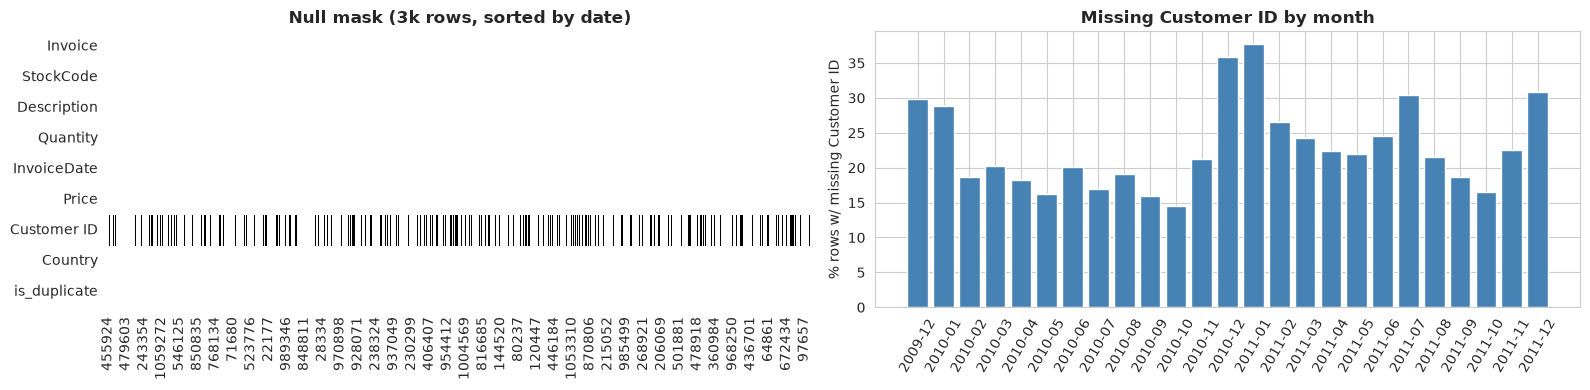

,% missing Customer ID
Country,
United Kingdom,24.5
EIRE,9.4
Germany,0.0
France,0.9
Netherlands,0.0


In [10]:
# pattern check: is missingness random?
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

sample = df.sort_values('InvoiceDate').sample(n=min(len(df), 3000), random_state=42)
sns.heatmap(sample.isna().transpose(), cmap='Grays', cbar=False, ax=axes[0])
axes[0].set_title('Null mask (3k rows, sorted by date)')

monthly_miss = df.assign(m=df['Customer ID'].isna()).groupby(df.InvoiceDate.dt.to_period('M')).m.mean() * 100
axes[1].bar(range(len(monthly_miss)), monthly_miss.values, color='steelblue')
axes[1].set_xticks(range(len(monthly_miss)), [str(p) for p in monthly_miss.index], rotation=60)
axes[1].set_ylabel('% rows w/ missing Customer ID')
axes[1].set_title('Missing Customer ID by month')

plt.tight_layout(); plt.show()

mid = df.assign(pid=df['Customer ID'].isna()).groupby('Country').pid.mean().mul(100)
top5 = df.Country.value_counts().head(5).index
display(mid.reindex(top5).round(1).to_frame('% missing Customer ID'))

With above visualization i want to, test whether missing `Customer ID` values occur completely at random (MCAR) or follow a distinct pattern.

* Time Trend: Missingness is non-random. It spikes heavily during peak holiday seasons (reaching 37% in Jan 2011 vs. ~15% in late 2010).
* Geographic Distribution: Anonymous orders are almost entirely confined to the home market (UK: 24,5%, EIRE : 9,4%). Core export market like Germany and the Netherlands maintain 0% missing IDs.

Since these represents real UK guest checkouts, I preserved these records for overall revenue calculations, but drop them prior to customer-level segmentation (RFM Analysis).

### Descriptive Statistics

In [11]:
# Inspect raw numerical fields to spot data quality issues and extreme outliers
rev_raw = df.Quantity * df.Price
num_desc = df[['Quantity', 'Price']].describe().T
rev_desc = rev_raw.describe().to_frame().T.rename(index={'count': 'Revenue (raw)'})
pd.concat([num_desc, rev_desc]).round(2)

,count,mean,std,min,25%,50%,75%,max
Quantity,1067371.0,9.94,172.71,-80995.00,1.00,3.0,10.00,80995.0
Price,1067371.0,4.65,123.55,-53594.36,1.25,2.1,4.15,38970.0
0,1067371.0,18.07,292.42,-168469.60,3.75,9.9,17.70,168469.6


* `Quantity` (-80,995 to +80,995): Heavily right-skewed (median is only 3 units), with symmetrical extreme minimums and maximums pointing to paired order cancellations.
* `Price` (-$53,594.36 to $38,970.00): Most items cost around $2.10 (median), but negative price entries reveal administrative fee adjustments or system logs.
* `Raw Revenue` (-$168,469.00 to $168,469.60): Calculated prior to filtering, showing that raw totals are heavily distorted by negative values and large adjustments.

In [12]:
# Evaluate distribution shape (skewness & kurtosis) and validate log-transformations
# effectiveness on positive sales data
pos = df[(df.Quantity > 0) & (df.Price > 0)]
rev_pos = pos.Quantity * pos.Price
rows = []
for name, s in [
    ('Quantity (pos)', pos.Quantity), ('Price (pos)', pos.Price), ('Revenue (pos)', rev_pos),
    ('log1p Quantity', np.log1p(pos.Quantity)), ('log1p Price', np.log1p(pos.Price)),
    ('log10 Revenue', np.log10(rev_pos)),
]:
    rows.append({'metric': name, 'skew': stats.skew(s), 'kurtosis': stats.kurtosis(s), 'max': s.max()})
pd.DataFrame(rows).set_index('metric').round(2)

,skew,kurtosis,max
metric,,,
Quantity (pos),459.99,276078.85,80995.00
Price (pos),231.44,78429.30,25111.09
Revenue (pos),612.10,475780.87,168469.60
log1p Quantity,1.06,1.29,11.30
log1p Price,1.13,3.79,10.13
log10 Revenue,0.13,0.63,5.23


* Raw Distribution: Severely distorted by high-value outliers (e.g., max order revenue of $168,469.60 pushes raw revenue kurtosis above 475,000).
* Log Transformations: `log1p` and `log10` effectively normalize feature distributions across all three metrics.

In [13]:
# Measure categorical cardinality and text consistency
cat_cols = ['Invoice', 'StockCode', 'Description', 'Country']
pd.DataFrame({
    'n_unique': [df[c].nunique() for c in cat_cols],
    'top_value': [df[c].value_counts().idxmax() for c in cat_cols],
    'top_freq': [int(df[c].value_counts().iloc[0]) for c in cat_cols],
    'top_freq_pct': [round(df[c].value_counts().iloc[0] / len(df) * 100, 1) for c in cat_cols],
}, index=cat_cols)

,n_unique,top_value,top_freq,top_freq_pct
Invoice,53628,537434,1350,0.1
StockCode,5305,85123A,5829,0.5
Description,5699,WHITE HANGING HEART T-LIGHT HOLDER,5918,0.6
Country,43,United Kingdom,981330,91.9


* `Country` (43 Unique): Heavily right-skewed toward the domestic UK market (91.9% of total rows).
* `StockCode` (5,305) vs. `Description` (5,598): Cardinality mismatch indicates multiple description strings assigned to single product codes.
* `Invoice` (53,628 unique): High order volume, with the single largest invoice containing 1,350 line items.
* `Top Item (85123A)`: WHITE HANGING HEARTH T-LIGHT HOLDER represents the most frequent item in the transactional log (5,918 rows).

### Univariate Analysis

All three monetary/quantity variables are massively right-tailed (skew 200+). Median Quantity is only ~3 but extreme bulk orders reach 80,995 units. On the log scale the distributions become well-behaved, which is why RFM quartile scoring later stays robust.

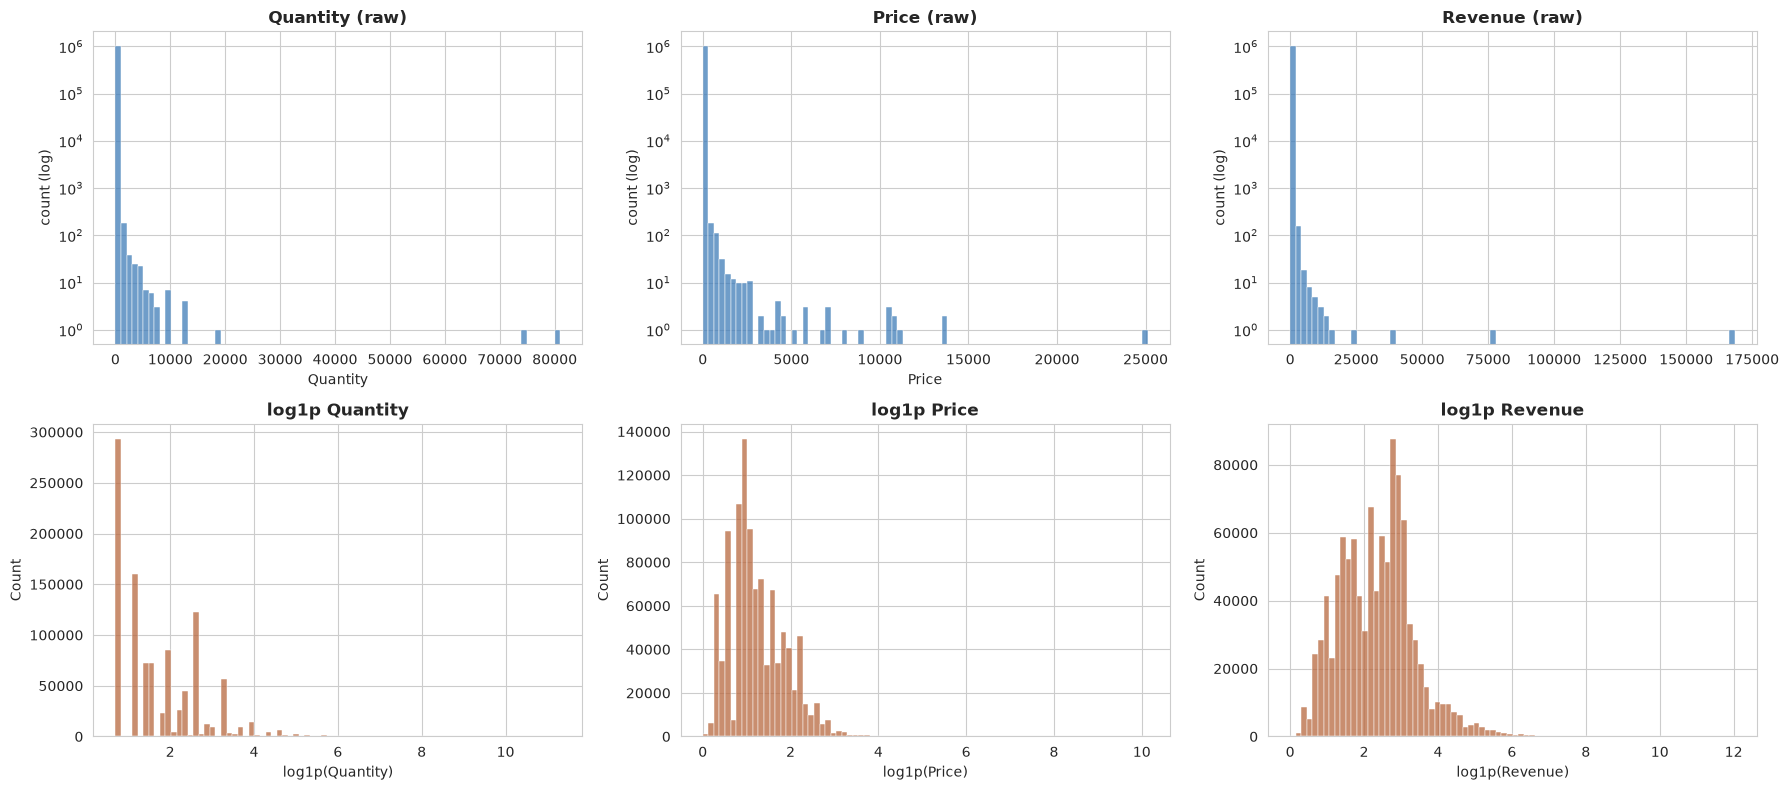

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))

for j, (name, series) in enumerate([('Quantity', pos.Quantity), ('Price', pos.Price), ('Revenue', rev_pos)]):
    sns.histplot(series, bins=80, ax=axes[0, j], legend=False, color='#3f7cb8')
    axes[0, j].set_title(f'{name} (raw)'); axes[0, j].set_yscale('log')
    axes[0, j].set_ylabel('count (log)')
    sns.histplot(np.log1p(series), bins=80, ax=axes[1, j], legend=False, color='#b8683f')
    axes[1, j].set_title(f'log1p {name}')
    axes[1, j].set_xlabel(f'log1p({name})')

plt.tight_layout(); plt.show()

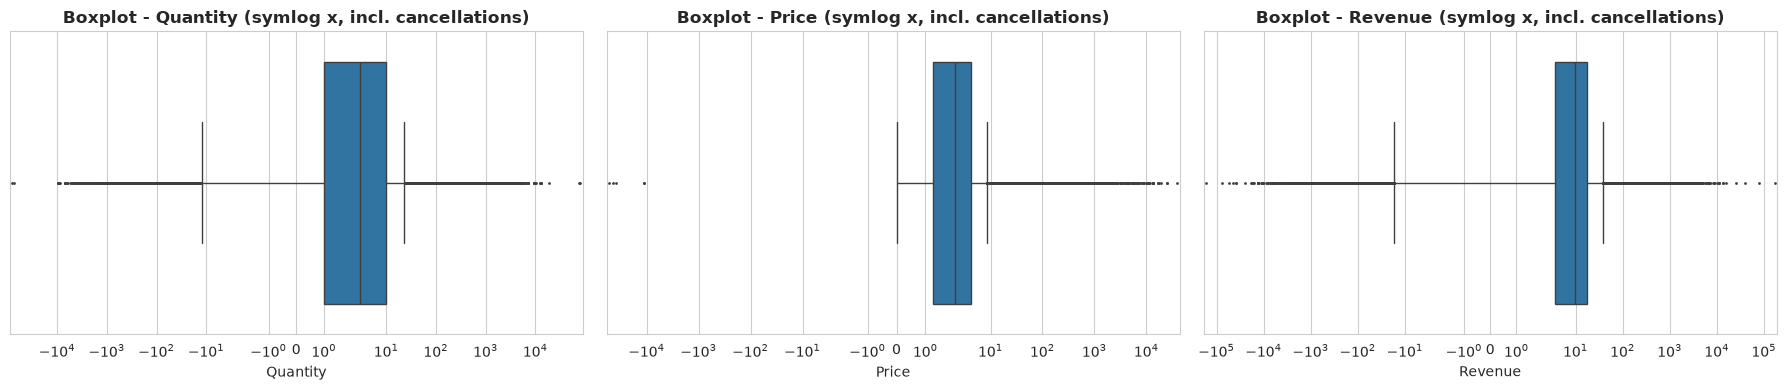

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.boxplot(x=df.Quantity, ax=axes[0], fliersize=1)
sns.boxplot(x=df.Price, ax=axes[1], fliersize=1)
sns.boxplot(x=rev_raw, ax=axes[2], fliersize=1)
for ax, name in zip(axes, ['Quantity', 'Price', 'Revenue']):
    ax.set_xlabel(name); ax.set_title(f'Boxplot - {name} (symlog x, incl. cancellations)')
    ax.set_xscale('symlog')
plt.tight_layout(); plt.show()

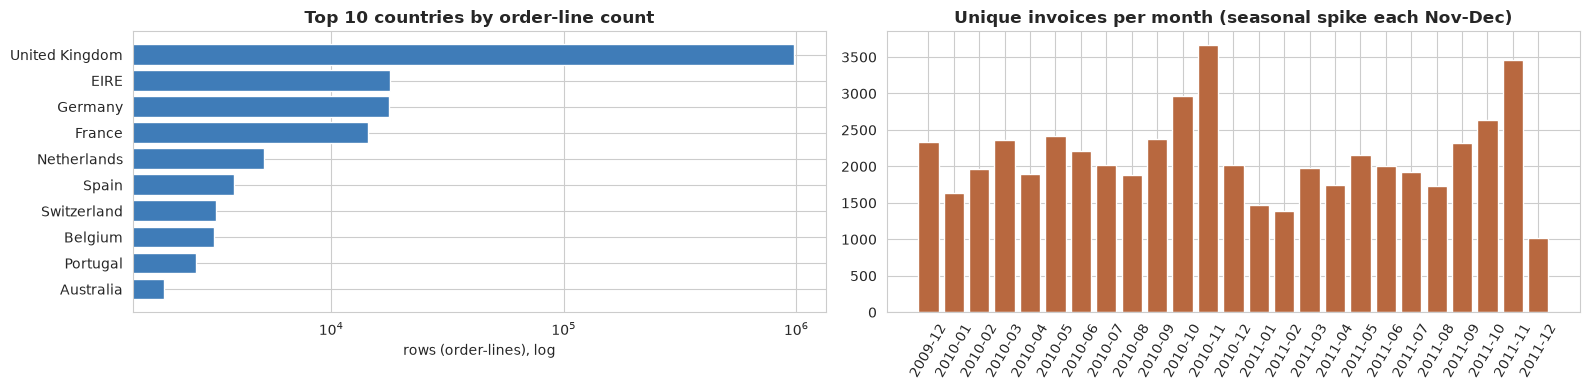

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
c10 = df.Country.value_counts().head(10).iloc[::-1]
axes[0].barh(range(len(c10)), c10.values, color='#3f7cb8')
axes[0].set_yticks(range(len(c10)), c10.index)
axes[0].set_xscale('log'); axes[0].set_xlabel('rows (order-lines), log')
axes[0].set_title('Top 10 countries by order-line count')

monthly = df.groupby(df.InvoiceDate.dt.to_period('M')).Invoice.nunique()
axes[1].bar(range(len(monthly)), monthly.values, color='#b8683f')
axes[1].set_xticks(range(len(monthly)), [str(p) for p in monthly.index], rotation=60)
axes[1].set_title('Unique invoices per month (seasonal spike each Nov-Dec)')
plt.tight_layout(); plt.show()

### Bivariate & Multivariate Analysis

- Quantity-Price correlation is ~0 -> large volumes come off *cheap unit-price* items (bulk deals), not expensive ones.
- November is the strongest revenue month every year (Christmas build-up); cancellations are a small but constant share.
- The UK alone generates ~90% of revenue.

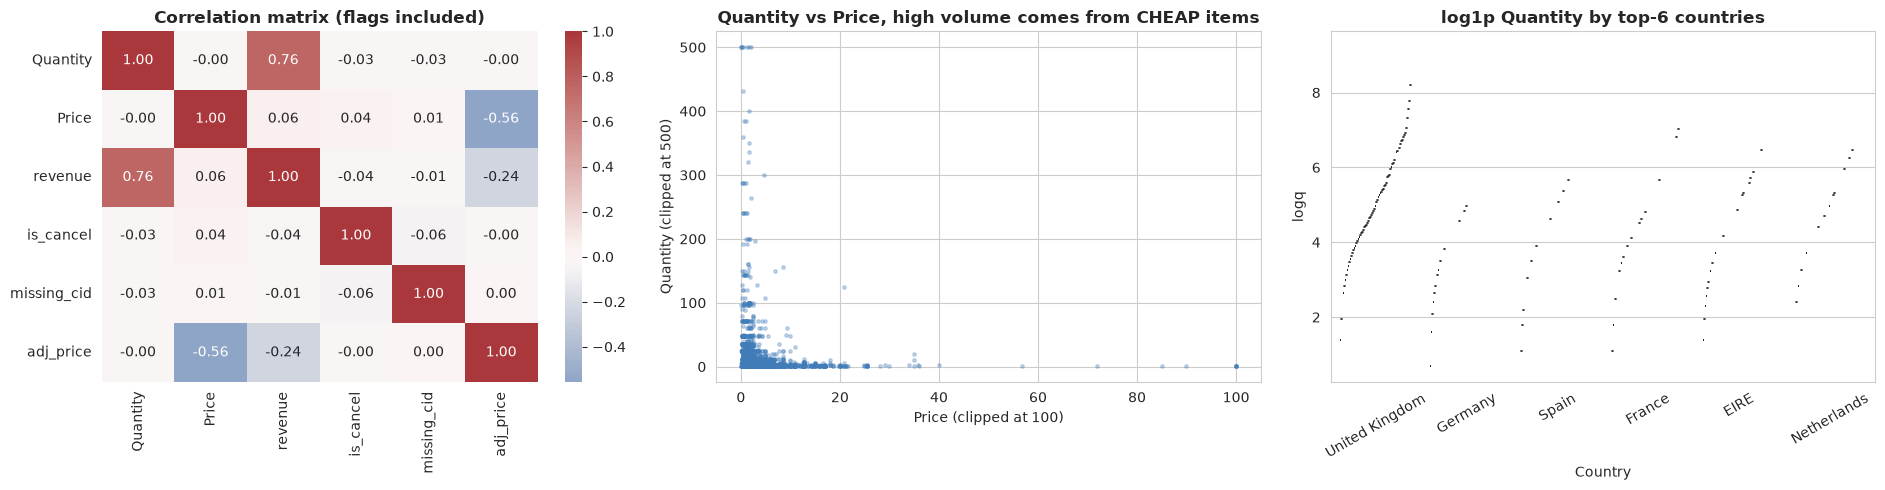

In [17]:
flags = df.assign(
    revenue=rev_raw,
    is_cancel=df.Invoice.str.startswith('C').astype(int),
    missing_cid=df['Customer ID'].isna().astype(int),
    adj_price=df.Price < 0,
)
corr = flags[['Quantity', 'Price', 'revenue', 'is_cancel', 'missing_cid', 'adj_price']].corr()

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0, ax=axes[0])
axes[0].set_title('Correlation matrix (flags included)')

samp = pos.sample(5000, random_state=1)
axes[1].scatter(samp.Price.clip(upper=100), samp.Quantity.clip(upper=500), s=6, alpha=.3, color='#3f7cb8')
axes[1].set_xlabel('Price (clipped at 100)'); axes[1].set_ylabel('Quantity (clipped at 500)')
axes[1].set_title('Quantity vs Price, high volume comes from CHEAP items')

top6c = pos.Country.value_counts().head(6)
vi = pos[pos.Country.isin(top6c.index)].assign(logq=np.log1p(pos.Quantity))
vi = vi.sample(n=min(len(vi), 120_000), random_state=0)
sns.violinplot(data=vi, x='Country', y='logq', hue='logq', palette='Blues', cut=0, inner='quartiles', ax=axes[2], legend=False)
axes[2].set_title('log1p Quantity by top-6 countries')
axes[2].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

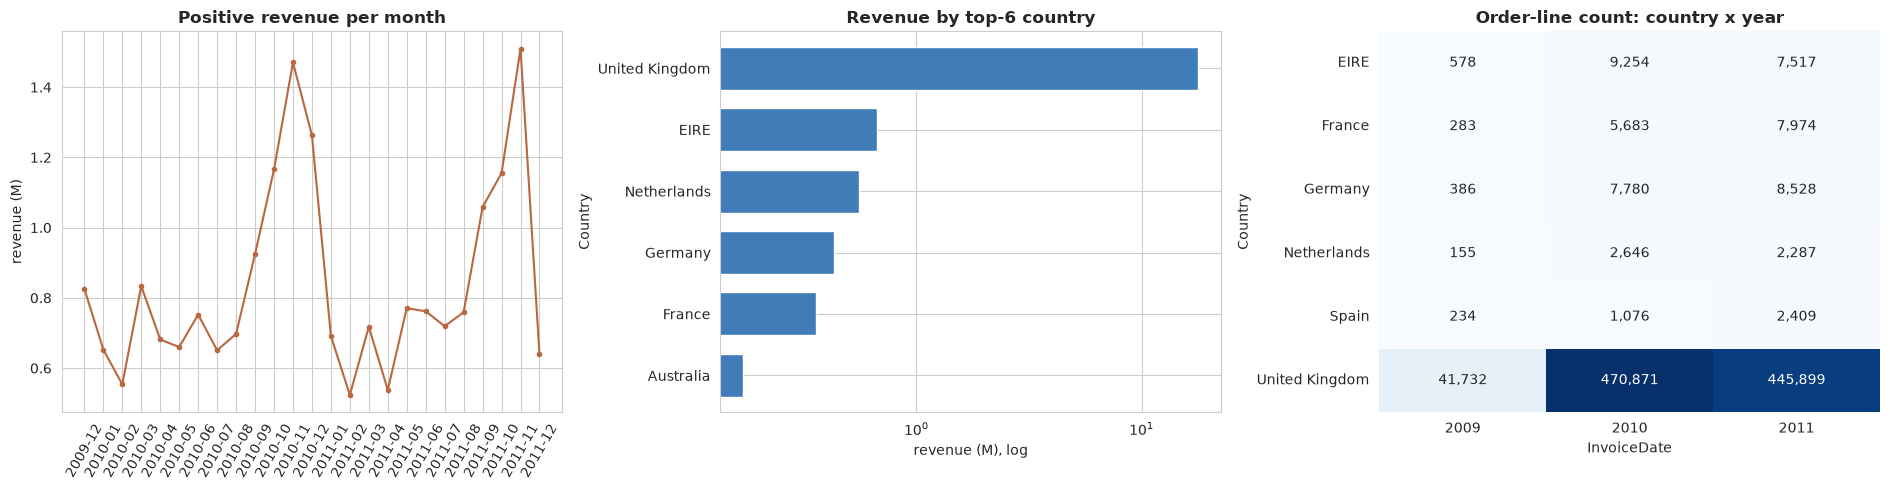

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
mrev = pos.assign(revenue=pos.Quantity * pos.Price).groupby(pos.InvoiceDate.dt.to_period('M')).revenue.sum() / 1e6
axes[0].plot(range(len(mrev)), mrev.values, color='#b8683f', marker='o', ms=3)
axes[0].set_xticks(range(len(mrev)), [str(p) for p in mrev.index], rotation=60)
axes[0].set_ylabel('revenue (M)'); axes[0].set_title('Positive revenue per month')

rc = pos.assign(revenue=pos.Quantity * pos.Price).groupby('Country').revenue.sum().nlargest(6)
(rc / 1e6).plot(kind='barh', color='#3f7cb8', width=.7, ax=axes[1])
axes[1].invert_yaxis(); axes[1].set_xscale('log'); axes[1].set_xlabel('revenue (M), log')
axes[1].set_title('Revenue by top-6 country')

xt = pd.crosstab(pos.loc[pos.Country.isin(top6c.index), 'Country'], pos.InvoiceDate.dt.year)
sns.heatmap(xt, annot=True, fmt=',.0f', cmap='Blues', ax=axes[2], cbar=False)
axes[2].set_title('Order-line count: country x year')
plt.tight_layout(); plt.show()

### Outlier & Anomaly Detection

**Domain Interpretation**: Treat extream values as real business events rather than data errors.

* **Drop bad-debt adjustments**: Remove `A...` invoices (StockCode `B`, with negative prices downs to -53,594) because they represents accounting entries rather than actual sales.
* **Filter manual enteries**: Exclude `M` (manual adjustment) rows from RFM metrics, but keep and flag them in the fact layer.
* **Net out bulk cancellations**: Pair and cancel matching transactions (for example, offset the +80,995 PAPER-CRAFT order with its next-day -80,995 `C...` cancellation).
* **Retain genuine wholesale behavior**: Keep remaining bulk orders (such as the 74,215-unit order for the MEDIUM CERAMIC TOP STORAGE JAR), as they reflect legitimate high-volume customer purchases.

In [19]:
def fences(s, name):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = (s < lo) | (s > hi)
    z = (s - s.mean()).abs() / s.std()
    print(f'{name:12s} IQR fence [{lo:10.2f}, {hi:10.2f}]  outside: {out.sum():>9,} ({out.mean():5.1%})   |z|>3: {(z > 3).sum():>7,} ({(z > 3).mean():5.1%})')

fences(df.Quantity, 'Quantity')
fences(pos.Price, 'Price')
fences(rev_raw, 'Revenue')

Quantity     IQR fence [    -12.50,      23.50]  outside:   116,489 (10.9%)   |z|>3:   1,266 ( 0.1%)
Price        IQR fence [     -3.07,       8.45]  outside:    81,634 ( 7.8%)   |z|>3:   1,047 ( 0.1%)
Revenue      IQR fence [    -17.18,      38.63]  outside:    90,922 ( 8.5%)   |z|>3:   1,127 ( 0.1%)


In [20]:
extreme = df.reindex(df.Quantity.abs().sort_values(ascending=False).head(8).index)
display(extreme[['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'Country']].assign(Revenue=extreme.Quantity * extreme.Price))

print('rows by invoice prefix (domain meaning):')
labels = {'C': 'C... = cancellation', 'A': 'A... = bad-debt adj.', '5': '5... = sales', '4': '4... = sales',
          '8': '8... = sales', '3': '3... = sales'}
pref = df.Invoice.str[0].value_counts().head(6)
display(pref.rename(index=lambda p: labels.get(p, p + '...')).to_frame('rows'))

print('cancelled rows with WRONG sign (positive quantity):', int((df.Invoice.str.startswith('C') & (df.Quantity > 0)).sum()))

del flags, vi, samp, extreme, pos, rev_pos, rev_raw
gc.collect()

,Invoice,StockCode,Description,Quantity,Price,Country,Revenue
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,United Kingdom,168469.6
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,United Kingdom,-168469.6
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,United Kingdom,77183.6
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,United Kingdom,-77183.6
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,Denmark,1915.2
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,Denmark,1296.0
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,Denmark,1296.0
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,Denmark,1274.4


rows by invoice prefix (domain meaning):


,rows
Invoice,
5... = sales,939382
4... = sales,108489
C... = cancellation,19494
A... = bad-debt adj.,6


cancelled rows with WRONG sign (positive quantity): 1


2627

### Data Product: Fact Layer + Cleaning Funnel

**Two-layer design** (per the CRM/dashboard spec):

| layer | used for | filter (`WHERE`-style clauses) |
|---|---|---|
| `retail_fact` — every row kept | sales-KPI dashboards (gross/returns/net), return rate | flags only: `~is_duplicate` |
| RFM / cleaned layer | customer analytics | `~is_duplicate & ~is_cancel & has_customer & Quantity>0 & Price>0 & is_product` |
| KPI product layer | revenue KPIs (guest check-outs included!) | `~is_duplicate & is_product & Quantity>0 & Price>0` |

Flags: `is_cancel` (invoice starts with `C`), `has_customer` (Customer ID present), `is_product` (StockCode not one of the non-product codes below), `is_duplicate` (excess identical-copy of the same order-line record).

### Data Product: Fact Layer & Cleaning Funnel
Data Model Architecture: Structured into three purposs-built views to support reporting, CRM analytics, and executive dashboard:

| Data Layer | Primary Use Case | Filter Criteria ( `WHERE` Clauses )
| --- | --- | --- |
| `retail_fact` | Base transaction layer for sales KPIs (gross, net, returns, and return rate) | Includes all records except exact duplicates (`~is_duplicate`) |
| `rfm_cleaned` | Customer segmentation, behavioral analysis, and RFM modeling | `~is_duplicate & ~is_cancel & has_customer & is_product & Quantity > 0 & Price > 0` |
| `kpi_product` | Revenue dashboards (includes guest checkouts without Customer IDs) | `~is_duplicate & is_product & Quantity > 0 & Price > 0` |

**Flag Definition**:
* `is_cancel` : Identifies cancelled orders or returns (Invoice start with `C`).
* `has_customer` : Confirms a valid Customer ID is attached to the transaction.
* `is_product` : Filters out non-inventory line items (e.g., postage, bank fees, manual adjustments).
* `is_duplicate` : Flags redundant exact-copy line items for removal


In [21]:
DUPLICATE_KEY = ['Invoice', 'StockCode', 'Quantity', 'Price', 'InvoiceDate', 'Customer ID']
NON_PRODUCT = {'POST', 'D', 'M', 'BANK CHARGES', 'C2', 'DOT', 'PADS', 'AMAZONFEE', 'CRUK'}

fact = df.copy()
fact['is_cancel'] = fact.Invoice.str.startswith('C')
fact['has_customer'] = fact['Customer ID'].notna()
fact['is_product'] = ~fact.StockCode.str.upper().isin(NON_PRODUCT)
fact['is_duplicate'] = fact.duplicated(subset=DUPLICATE_KEY, keep='first')   # excess copies flagged, originals kept
fact['Revenue'] = fact.Quantity * fact.Price

print('fact layer:', fact.shape)
display(fact[['is_cancel', 'has_customer', 'is_product', 'is_duplicate']].mean().mul(100).round(2).to_frame('% of rows'))
fact.to_parquet('../data/processed/retail_fact.parquet', index=False)
print('saved -> ../data/processed/retail_fact.parquet (all rows kept)')

del df, excess
gc.collect()

fact layer: (1067371, 13)


,% of rows
is_cancel,1.83
has_customer,77.23
is_product,99.47
is_duplicate,3.22


saved -> ../data/processed/retail_fact.parquet (all rows kept)


64578

In [22]:
# cleaning funnel for the RFM layer starts from the flagged fact
steps = {
    '- exact duplicate rows (flagged excess copies)': ~fact.is_duplicate,
    '- cancellations (C invoices)': ~fact.is_cancel,
    '- rows w/o Customer ID': fact.has_customer,
    '- Quantity <= 0': fact.Quantity > 0,
    '- Price <= 0': fact.Price > 0,
    '- non-product StockCodes': fact.is_product,
}
cum = pd.Series(True, index=fact.index)
log = []
for label, m in steps.items():
    cum &= m
    log.append({'step': label, 'rows_kept': int(cum.sum()), 'pct_kept': round(cum.mean() * 100, 2)})
display(pd.DataFrame(log))

cleaned = fact[cum].copy()
cleaned['Customer ID'] = cleaned['Customer ID'].astype(int)
print('cleaned:', cleaned.shape, '| invoices:', cleaned.Invoice.nunique(), '| customers:', cleaned['Customer ID'].nunique(),
      '| range:', cleaned.InvoiceDate.min(), '->', cleaned.InvoiceDate.max())

cleaned.to_parquet('../data/processed/retail_cleaned.parquet', index=False)
print('saved -> ../data/processed/retail_cleaned.parquet (RFM layer)')

,step,rows_kept,pct_kept
0,- exact duplicate rows (flagged excess copies),1033034,96.78
1,- cancellations (C invoices),1013930,94.99
2,- rows w/o Customer ID,779493,73.03
3,- Quantity <= 0,779493,73.03
4,- Price <= 0,779423,73.02
5,- non-product StockCodes,776622,72.76


cleaned: (776622, 13) | invoices: 36639 | customers: 5861 | range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00
saved -> ../data/processed/retail_cleaned.parquet (RFM layer)


In [23]:
# layer totals: the dashboard must NOT use the RFM layer (it would understate revenue ~13%)
kpi_lines = fact[~fact.is_duplicate & fact.is_product & (fact.Quantity > 0) & (fact.Price > 0)]
rfm_lines = cleaned
summary = pd.DataFrame({
    'rows': [len(kpi_lines), len(rfm_lines)],
    'gross revenue (GBP)': [kpi_lines.Revenue.sum(), rfm_lines.Revenue.sum()],
    'coverage of KPI revenue': [100.0, round(rfm_lines.Revenue.sum() / kpi_lines.Revenue.sum() * 100, 1)],
}, index=['KPI layer (guest-inclusive product lines)', 'RFM layer (identified customers only)'])
summary['revenue'] = summary['gross revenue (GBP)'].map(lambda v: f'£{v:,.0f}')
display(summary[['rows', 'revenue', 'coverage of KPI revenue']])
print('>> RFM panel footnote: "RFM covers identified customers only (~87% of revenue)" so totals do not look broken.')

del kpi_lines, rfm_lines, summary
gc.collect()

,rows,revenue,coverage of KPI revenue
KPI layer (guest-inclusive product lines),1003468,"£19,666,120",100.0
RFM layer (identified customers only),776622,"£17,072,526",86.8


>> RFM panel footnote: "RFM covers identified customers only (~87% of revenue)" so totals do not look broken.


0

### Return-rate view (from the fact layer, guest-inclusive)

Conventions (documented in README):
- **Value-based**: monthly rate = |cancelled value| / gross product-sales value *in the same month*. Invoice-count versions give different numbers this notebook uses value-based.
- **Headline metric attributed to the cancellation month** (simple rule, works for every row, guests included).
- **Secondary view** aligns cancellations to the original order month for the ~85% of cancellation lines that can be matched to an earlier sale of the same customer+product; the rest stay unpaired.
- Spikes in Q1 and post-peak months are **expected**, not bugs returns arrive late from Q4 order cycles.
- First month (2009-12) and last month (2011-12, cut off on the 9th) are **partial** and marked plainly on the chart.

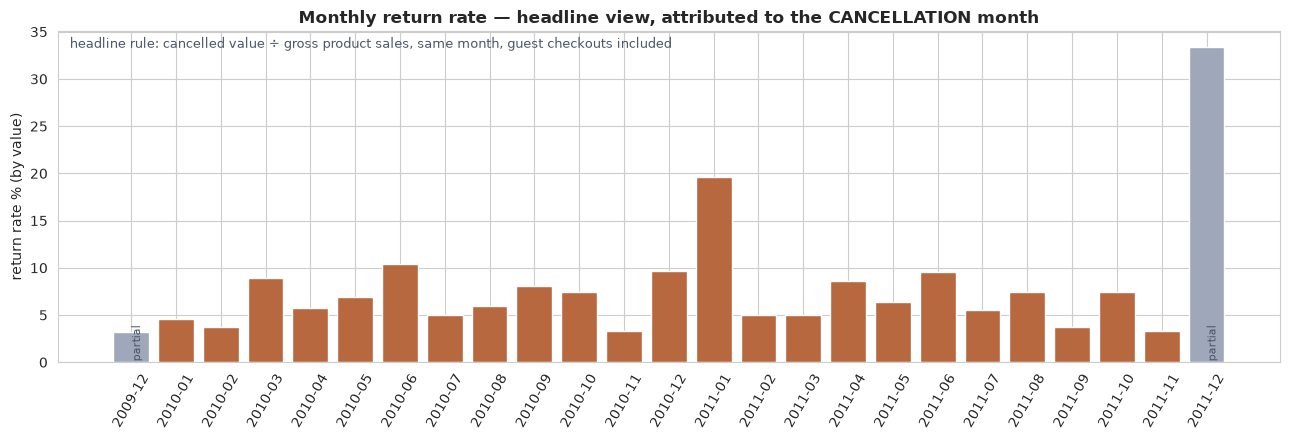

overall: returns £1,462,051 vs gross £19,666,120 -> 7.4%


In [24]:
sales_lines = fact[~fact.is_duplicate & fact.is_product & (fact.Quantity > 0) & (fact.Price > 0)]
cancel_lines = fact[fact.is_cancel & ~fact.is_duplicate]
month = lambda s: s.InvoiceDate.dt.to_period('M')

gross = sales_lines.assign(m=month(sales_lines)).groupby('m').Revenue.sum()
returns = cancel_lines.assign(m=month(cancel_lines)).groupby('m').Revenue.sum().abs()
rate = (returns / gross * 100).reindex(gross.index).fillna(0)

fig, ax = plt.subplots(figsize=(13, 4.5))
colors = ['#9fa8ba' if str(p) in ('2009-12', '2011-12') else '#b8683f' for p in rate.index]
ax.bar(range(len(rate)), rate.values, color=colors)
for i, p in enumerate(rate.index):
    if str(p) in ('2009-12', '2011-12'):
        ax.text(i, .1, 'partial', rotation=90, fontsize=8, va='bottom', color='#4a5568')
ax.set_xticks(range(len(rate)), [str(p) for p in rate.index], rotation=60)
ax.set_ylabel('return rate % (by value)')
ax.set_title('Monthly return rate — headline view, attributed to the CANCELLATION month')
ax.text(.01, .95, 'headline rule: cancelled value ÷ gross product sales, same month, guest checkouts included',
        transform=ax.transAxes, fontsize=9, color='#4a5568')
plt.tight_layout(); plt.show()
print(f'overall: returns £{returns.sum():,.0f} vs gross £{gross.sum():,.0f} -> {returns.sum() / gross.sum() * 100:.1f}%')

paired cancellation lines: 16,330/19,104 (85%) | unpaired: 2,774 (mostly guest cancels)


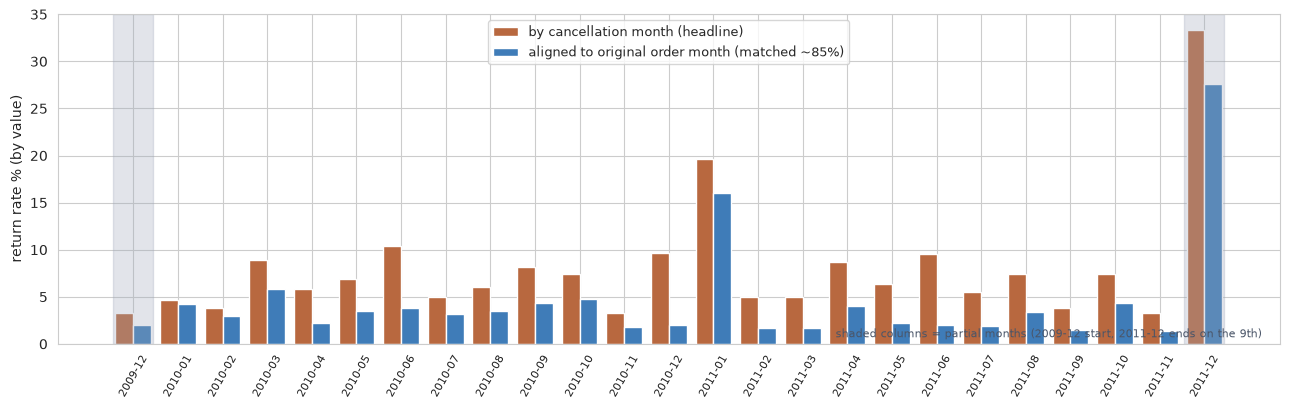

3

In [25]:
# secondary view: align each cancellation to the ORIGINAL order month (matched subset only)
base_pos = fact[~fact.is_duplicate & ~fact.is_cancel & fact.has_customer & (fact.Quantity > 0)]
pairs = base_pos.groupby(['Customer ID', 'StockCode'])          # fastest reasonable lookup

orig_months = []
n_unpaired = 0
for cid, sc, dt in zip(cancel_lines['Customer ID'], cancel_lines.StockCode, cancel_lines.InvoiceDate):
    if pd.isna(cid):
        n_unpaired += 1; orig_months.append(None); continue
    try:
        g = pairs.get_group((cid, sc))
    except KeyError:
        n_unpaired += 1; orig_months.append(None); continue
    g = g[g.InvoiceDate < dt]
    if len(g) == 0:
        n_unpaired += 1; orig_months.append(None)
    else:
        orig_months.append(g.InvoiceDate.max() - pd.Timedelta(days=0))     # keep the full timestamp

cancel_lines = cancel_lines.assign(orig_date=pd.to_datetime(orig_months))
aligned = cancel_lines.dropna(subset=['orig_date'])
n_unpaired = len(cancel_lines) - len(aligned)
print(f'paired cancellation lines: {len(aligned):,}/{len(cancel_lines):,} ({len(aligned) / len(cancel_lines):.0%}) | unpaired: {n_unpaired:,} (mostly guest cancels)')

a = aligned.assign(m=aligned.orig_date.dt.to_period('M')).groupby('m').Revenue.sum().abs()
ret2 = (a / gross.reindex(a.index).fillna(1e-9) * 100).reindex(gross.index).fillna(0)

fig, ax = plt.subplots(figsize=(13, 4.2))
idx = rate.index
h1 = rate.values; h2 = ret2.values
ax.bar(np.arange(len(idx)) - .2, h1, width=.4, label='by cancellation month (headline)', color='#b8683f')
ax.bar(np.arange(len(idx)) + .2, h2, width=.4, label='aligned to original order month (matched ~85%)', color='#3f7cb8')
ax.set_xticks(range(len(idx)), [str(p) for p in idx], rotation=60, fontsize=8)
ax.set_ylabel('return rate % (by value)')
for i, p in enumerate(idx):
    if str(p) in ('2009-12', '2011-12'):
        ax.axvspan(i - .45, i + .45, color='#9fa8ba', alpha=.3)
ax.text(.985, .02, 'shaded columns = partial months (2009-12 start, 2011-12 ends on the 9th)',
        transform=ax.transAxes, ha='right', fontsize=8, color='#4a5568')
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

del base_pos, pairs, aligned, sales_lines, a, ret2, gross, cancel_lines
del fact                                   # RFM section only needs `cleaned`
gc.collect()

### 8. RFM  Recency / Frequency / Monetary Segments

| Metric | Meaning | Formula per Customer ID |
|---|---|---|
| Recency | how recent the last purchase was | `snapshot - max(InvoiceDate)`, in days |
| Frequency | how often they buy | number of unique Invoices |
| Monetary | how big their spend is | sum(Quantity x Price) |

Conventions (documented in README):
- `snapshot = max(InvoiceDate) + 1 day` = **2011-12-10** (not "today") so re-runs stay comparable.
- **R** & **M** use data quintiles (robust to the heavy tail); **R is inverted** (fewer days = better).
- **F uses fixed business thresholds** instead of quintile ranks: `1 | 2-3 | 4-6 | 7-12 | 13+` invoices -> scores 1-5. Quintiles with `rank(method='first')` split customers with identical frequency into different scores by arbitrary row order; fixed bins keep the story explainable: *"Champions bought 7+ times and are recent."*
- Segments compress into four business groups covering the full R x F grid (no empty bucket, no `Others`):
  **Champions** = recent & 7+ invoices | **Loyal** = every other recent customer (R>=3), incl. 1-2-time buyers | **At Risk** = 4+ invoices historically but inactive (R<=2) | **Lost** = inactive and infrequent (R<=2 & F<=2).
- M is not part of the rules; it is used to **prioritise inside a segment** (action list = highest Monetary first).
- RFM covers **identified customers only (~87% of KPI revenue)**; guest check-outs live in the fact layer.

In [26]:
snapshot = cleaned.InvoiceDate.max() + pd.Timedelta(days=1)
rfm = cleaned.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot - x.max()).days),
    Frequency=('Invoice', 'nunique'),
    Monetary=('Revenue', 'sum'),
).astype({'Recency': int})
print(f'snapshot: {snapshot:%Y-%m-%d %H:%M}  |  {len(rfm):,} customers')
print('Frequency quantiles confirmed:', rfm.Frequency.quantile([.5, .75, .9]).round(1).to_dict())
rfm.describe().T.round(2)

snapshot: 2011-12-10 12:50  |  5,861 customers
Frequency quantiles confirmed: {0.5: 3.0, 0.75: 7.0, 0.9: 13.0}


,count,mean,std,min,25%,50%,75%,max
Recency,5861.0,200.94,209.20,1.00,26.00,96.00,379.00,739.00
Frequency,5861.0,6.25,12.77,1.00,1.00,3.00,7.00,376.00
Monetary,5861.0,2912.90,14299.97,2.95,338.13,854.99,2237.12,580987.04


In [27]:
R_QUINT = [5, 4, 3, 2, 1]          # fewer days = better
F_EDGES = [0, 1, 3, 6, 12, np.inf] # 1 | 2-3 | 4-6 | 7-12 | 13+  invoices

rfm['R'] = pd.qcut(rfm.Recency, 5, labels=R_QUINT).astype(int)
rfm['F'] = pd.cut(rfm.Frequency, F_EDGES, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M'] = pd.qcut(rfm.Monetary, 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment(r, f):
    if r >= 4 and f >= 4: return 'Champions'   # recent + 7+ invoices
    if r >= 3:            return 'Loyal'       # all other recent customers, incl. 1-2-time buyers
    if f >= 3:            return 'At Risk'     # 4+ invoices historically but inactive lately
    return 'Lost'                              # inactive and infrequent

rfm['Segment'] = [segment(r, f) for r, f in zip(rfm.R, rfm.F)]
assert not rfm.Segment.isna().any()
counts = rfm.Segment.value_counts()
display(counts.to_frame('customers').assign(pct=lambda d: (d.customers / len(rfm) * 100).round(1)))
display(rfm.groupby('Segment')[['Recency', 'Frequency', 'Monetary']].agg(['mean', 'median']).round(1))
print('R x F coverage map (segment per cell):')
grid = pd.DataFrame(index=range(1, 6), columns=range(1, 6), dtype=object)
for r in range(1, 6):
    for f in range(1, 6):
        grid.loc[r, f] = segment(r, f)
display(grid)

,customers,pct
Segment,,
Loyal,2428,41.4
Lost,1887,32.2
Champions,1092,18.6
At Risk,454,7.7


Recency        Frequency        Monetary        
             mean median      mean median     mean  median
Segment                                                   
At Risk     350.0  361.0       6.9    5.0   2700.1  1383.3
Champions    18.8   15.0      19.2   13.0  10191.8  4456.0
Lost        445.3  423.0       1.5    1.0    520.4   321.6
Loyal        65.1   56.0       4.0    3.0   1538.4   874.5

R x F coverage map (segment per cell):


,1,2,3,4,5
1,Lost,Lost,At Risk,At Risk,At Risk
2,Lost,Lost,At Risk,At Risk,At Risk
3,Loyal,Loyal,Loyal,Loyal,Loyal
4,Loyal,Loyal,Loyal,Champions,Champions
5,Loyal,Loyal,Loyal,Champions,Champions


,Segment,Monetary (GBP),Frequency,Recency
Customer ID,,,,
12346,At Risk,77556.46,12,326
16754,At Risk,65500.07,29,372
13093,At Risk,54144.25,55,276
17850,At Risk,51208.87,155,372
13902,At Risk,34023.26,5,632
15749,Lost,44534.30,3,235
13687,Lost,11880.84,1,438
18052,Lost,10877.18,1,565
14028,Lost,10396.50,3,550


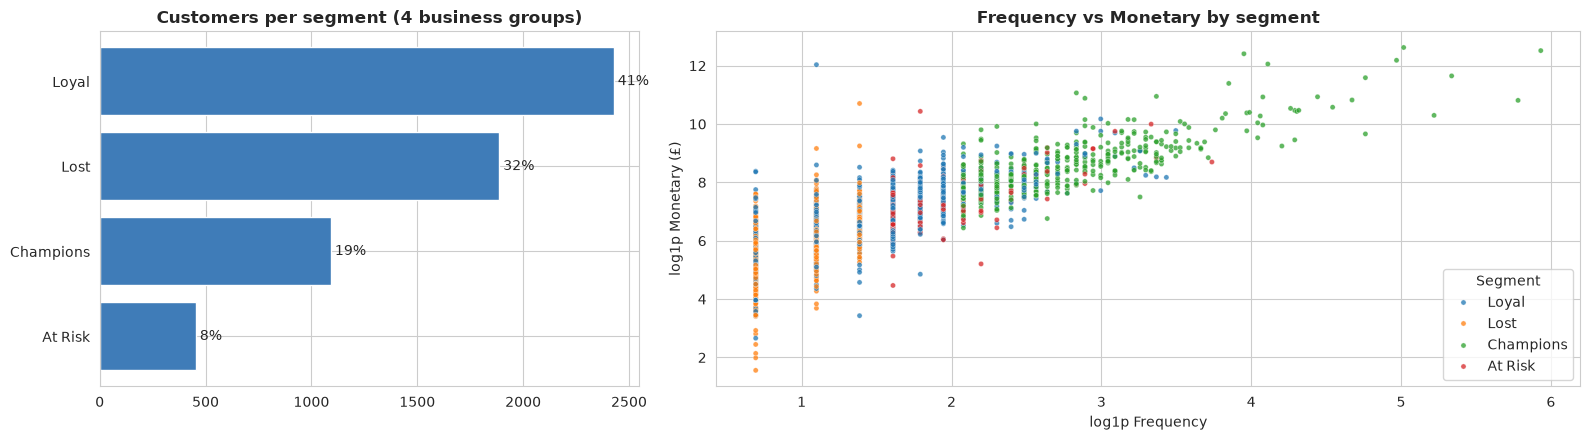

In [28]:
# within-segment prioritisation by Monetary the dashboard "action list" column
watchlist = ['At Risk', 'Lost']
top5 = (rfm[rfm.Segment.isin(watchlist)]
        .sort_values(['Segment', 'Monetary'], ascending=[True, False])
        .groupby('Segment').head(5)
        [['Segment', 'Monetary', 'Frequency', 'Recency']])
display(top5.rename(columns={'Monetary': 'Monetary (GBP)'}))

# single-figure insight: segment counts + F-vs-M spread
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1, 1.6]})
order = counts.sort_values()
axes[0].barh(range(len(order)), order.values, color='#3f7cb8')
axes[0].set_yticks(range(len(order)), order.index)
for i, (seg, n) in enumerate(order.items()):
    axes[0].text(n, i, f' {n / len(rfm):.0%}', va='center')
axes[0].set_title('Customers per segment (4 business groups)')

samp = rfm.sample(min(len(rfm), 2500), random_state=0)
samp = samp.assign(logF=np.log1p(samp.Frequency), logM=np.log1p(samp.Monetary))
sns.scatterplot(data=samp, x='logF', y='logM', hue='Segment', palette='tab10', s=14, alpha=.75, ax=axes[1])
axes[1].set_xlabel('log1p Frequency'); axes[1].set_ylabel('log1p Monetary (£)')
axes[1].set_title('Frequency vs Monetary by segment')
plt.tight_layout(); plt.show()

## Insights & Data-Prep Action Plan

**Key takeaways**

* 1,067,371 rows / 8 cols, Dec 2009 -> Dec 2011, **all values in GBP (£)**. 34,337 excess duplicate rows (£561.5k ≈ 2.9% sensitivity) are flagged `is_duplicate` and excluded by default. This assumption is documented in the README.
* **Missingness is structural, not random:** 22.8% of rows lack `Customer ID` (guest check-outs, clustered in time & country). These rows keep contributing revenue in the fact layer; RFM covers identified customers only (**~87% of KPI revenue**). The dashboard's RFM panel states this so totals do not look broken.
* Traps handled by flags: `C...` cancellations (19k rows), `A...` bad-debt adjustments, `M` manuals, non-product StockCodes. The +80,995 PAPER-CRAFT bulk order mirrors a `C...` cancellation of -80,995 the next day.
* Quantity / Price / Revenue have violent right tails (skew 200-600) that collapse to near-normal on log1p/log10. Keep logged versions for modelling; RFM scoring is robust as-is.
* Quantity vs Price correlation ~ 0: bulk volume sits on *low unit-price* items; UK ~ 90% of revenue; revenue peaks every November (Christmas).
* **Return rate ≈ 7.4% of gross product value**, headline rule = cancelled value ÷ gross product value per *cancellation* month. Q1 spikes are expected (late cancellations of Q4 orders). 2009-12 and 2011-12 are partial months.
* Segments (4 business groups, fixed-F bins `1 | 2-3 | 4-6 | 7-12 | 13+`): Champions 18.6% · Loyal 41.4% · At Risk 7.7% · Lost 32.2%; full R x F grid mapped, no `Others` bucket; Monetary prioritises within a segment (action list). Top customer (ID 18102): 145 invoices / **£580,987** (deduplicated).

**Action plan**

1. Use `retail_fact.parquet` for sales dashboards and `retail_cleaned.parquet` for CRM/RFM. Show gross sales, returns and net revenue as **three separate figures** on the dashboard instead of a single combined "revenue" number, and add the RFM-coverage footnote (~87%).
2. Keep the `snapshot = last invoice + 1 day` convention (2011-12-10) so recomputes stay consistent.
3. For ML on transaction rows: log-transform monetary columns; standardise numeric features only after the train/test split.
4. Feature ideas beyond RFM: time since first purchase, avg basket value, return share (`is_cancel`) per customer, product-category diversity, tenure + monthly activity patterns.
5. Validate segments/clusters over time (train on months till mid-2011, validate on the rest).
6. Sensitivity checks to re-run if sources change: duplicate-flag impact (~2.9% revenue), % of matched cancellation lines (85%), RFM share of KPI revenue (87%).